# Visão Computacional
# Detecção de queimadas (campo) e extensão para danos em estruturas (cidade)

| Integrante | RM |
| --- | --- |
| Geandro  | 562316 |
| Lucas Vero  | 564202 |
| Roberto Eduardo  | 564537 |

**Projeto:** Sentinela do Território CitizenTech (Global Solution 2026)

Este notebook treina e compara três modelos pré-treinados diferentes
(MobileNetV2, EfficientNetB0 e ResNet50) no mesmo problema detectar
incêndio em imagens de satélite para escolher qual deles funciona melhor.

## 1. O problema ambiental e o papel das imagens de satélite

Queimadas em áreas de vegetação são um dos riscos que o projeto **Sentinela do
Território** monitora. Um cidadão pode relatar uma queimada pelo assistente de voz
(módulo de PLN), mas esse relato é uma percepção humana pode estar errado, exagerado ou já ter sido resolvido. Imagens de satélite da região relatada dão uma **segunda fonte de evidência**, independente do relato, para confirmar ou não a ocorrência antes de acionar uma equipe.

Este notebook treina um classificador binário (**com incêndio** / **sem incêndio**), a partir de imagens de satélite, usando transferência de aprendizado (*transfer learning*): aproveitamos um modelo já treinado em milhões de imagens (ImageNet) e substituímos apenas a camada final por uma camada de saída binária, treinada com o dataset de queimadas. Isso exige muito menos dados e tempo de treino do que treinar uma rede do zero essencial em um projeto acadêmico com prazo curto.


In [ ]:
# Alterar o tipo de ambiente de execução > GPU (T4)
import tensorflow as tf
print("TensorFlow:", tf.__version__)
print("GPU disponível:", tf.config.list_physical_devices("GPU"))


TensorFlow: 2.21.0
GPU disponível: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [ ]:
# Modelo usado nas seções 1 a 13 (treino único, mais simples). A comparação dos três modelos de verdade acontece na seção 14, mais abaixo, sem precisar mudar nada aqui.
MODELO = "mobilenet_v2"

TAMANHO_IMAGEM = (224, 224)
TAMANHO_LOTE = 32
SEED = 42


## 2. Dataset: Wildfire Prediction Dataset (Kaggle)

O dataset indicado no anexo da disciplina é o
[**Wildfire Prediction Dataset**](https://www.kaggle.com/datasets/abdelghaniaaba/wildfire-prediction-dataset), com imagens de satélite já separadas em pastas `train`, `valid` e `test`, cada uma com as subpastas `wildfire` e `nowildfire`.

### Como baixar

1. No Kaggle, em *Account* → *Settings* → *API*, clique em **Generate New Token** e copie o valor mostrado (começa com `KGAT_`).
2. No Colab, clique no ícone de **chave** (🔑 *Secrets*) na barra lateral esquerda.
3. Clique em **Add new secret**.
4. Em "Name", digite exatamente `KAGGLE_API_TOKEN`. Em "Value", cole o token.
5. Ative o botão **Notebook access** ao lado do secret que você acabou de criar.
6. Rode a célula abaixo.

In [ ]:
# Baixar o dataset via kagglehub, usando o token nos Secrets
import os
from pathlib import Path

!pip install -q kagglehub
import kagglehub
from google.colab import userdata

os.environ["KAGGLE_API_TOKEN"] = userdata.get("KAGGLE_API_TOKEN")

caminho_baixado = kagglehub.dataset_download("abdelghaniaaba/wildfire-prediction-dataset")
CAMINHO_DADOS = Path(caminho_baixado)
print("Pasta de dados:", CAMINHO_DADOS)
print("Conteúdo:", list(CAMINHO_DADOS.iterdir()))


Using Colab cache for faster access to the 'wildfire-prediction-dataset' dataset.
Pasta de dados: /kaggle/input/wildfire-prediction-dataset
Conteúdo: [PosixPath('/kaggle/input/wildfire-prediction-dataset/valid'), PosixPath('/kaggle/input/wildfire-prediction-dataset/test'), PosixPath('/kaggle/input/wildfire-prediction-dataset/train')]


In [ ]:
import shutil
from pathlib import Path

CAMINHO_DADOS_GRAVAVEL = Path("/content/dados_queimada")
if not CAMINHO_DADOS_GRAVAVEL.exists():
    print("Copiando para uma pasta com permissão de escrita...")
    shutil.copytree(CAMINHO_DADOS, CAMINHO_DADOS_GRAVAVEL)
CAMINHO_DADOS = CAMINHO_DADOS_GRAVAVEL
print("Pasta de dados (gravável):", CAMINHO_DADOS)

Copiando para uma pasta com permissão de escrita...
Pasta de dados (gravável): /content/dados_queimada


### Limpeza: remover imagens corrompidas

Datasets baixados da internet às vezes trazem arquivos corrompidos (um JPEG que não terminou de ser gravado, por exemplo). Se isso não for tratado, o treinamento quebra no meio às vezes depois de já ter rodado várias etapas com um erro como `jpeg::Uncompress failed`. A célula abaixo verifica todas as imagens antes de treinar e remove as que não abrem corretamente, registrando
quantas foram removidas (tratamento de dado inválido, parte da robustez esperada do projeto).


In [ ]:
import tensorflow as tf

def remover_imagens_corrompidas(pasta: Path) -> int:
    removidas = 0
    extensoes = ("*.jpg", "*.jpeg", "*.png")
    for extensao in extensoes:
        for caminho in pasta.rglob(extensao):
            try:
                dados = tf.io.read_file(str(caminho))
                tf.io.decode_image(dados, channels=3)
            except Exception:
                caminho.unlink()
                removidas += 1
    return removidas

for particao in ("train", "valid", "test"):
    pasta = CAMINHO_DADOS / particao
    if pasta.exists():
        n = remover_imagens_corrompidas(pasta)
        if n:
            print(f"{particao}: {n} imagem(ns) corrompida(s) removida(s).")
        else:
            print(f"{particao}: nenhuma imagem corrompida encontrada.")


train: 1 imagem(ns) corrompida(s) removida(s).
valid: nenhuma imagem corrompida encontrada.
test: 1 imagem(ns) corrompida(s) removida(s).


## 3. Organização das pastas e exemplos visuais

Confirma quantas imagens existem por classe em cada partição (treino, validação,
teste) e mostra alguns exemplos de cada classe, para garantir que os dados foram
baixados corretamente antes de treinar.


In [ ]:
import matplotlib.pyplot as plt
from pathlib import Path

def contar_por_classe(pasta: Path):
    contagem = {}
    for classe_dir in sorted(pasta.iterdir()):
        if classe_dir.is_dir():
            contagem[classe_dir.name] = len(list(classe_dir.glob("*.jpg"))) + len(list(classe_dir.glob("*.png")))
    return contagem

for particao in ("train", "valid", "test"):
    pasta = CAMINHO_DADOS / particao
    if pasta.exists():
        print(f"{particao}: {contar_por_classe(pasta)}")


train: {'nowildfire': 14499, 'wildfire': 15750}
valid: {'nowildfire': 2820, 'wildfire': 3480}
test: {'nowildfire': 2820, 'wildfire': 3479}


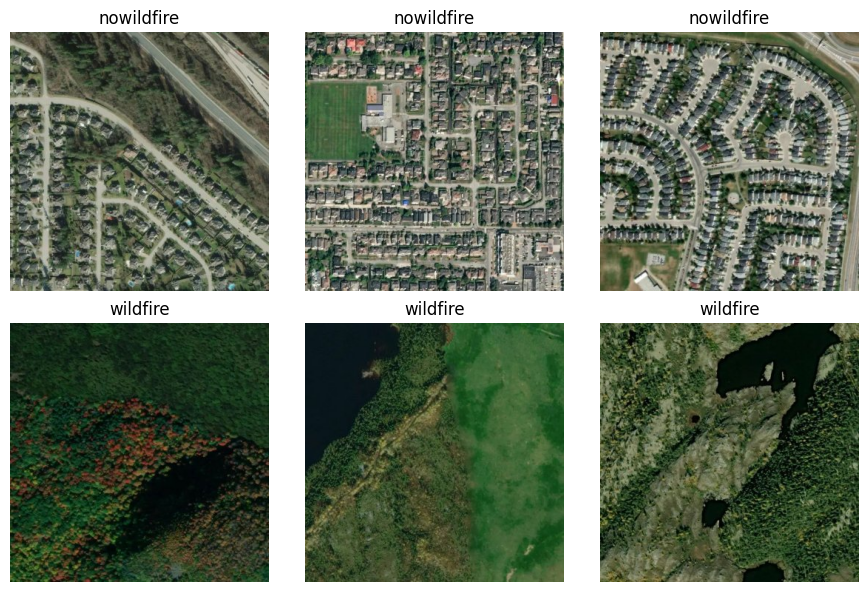

In [ ]:
# Exemplos visuais: 3 imagens de cada classe do treino
import random

pasta_treino = CAMINHO_DADOS / "train"
classes = sorted([p.name for p in pasta_treino.iterdir() if p.is_dir()])

fig, eixos = plt.subplots(len(classes), 3, figsize=(9, 3 * len(classes)))
random.seed(SEED)
for i, classe in enumerate(classes):
    arquivos = list((pasta_treino / classe).glob("*.jpg")) + list((pasta_treino / classe).glob("*.png"))
    amostras = random.sample(arquivos, min(3, len(arquivos)))
    for j, caminho in enumerate(amostras):
        img = plt.imread(caminho)
        eixo = eixos[i][j] if len(classes) > 1 else eixos[j]
        eixo.imshow(img)
        eixo.set_title(classe)
        eixo.axis("off")
plt.tight_layout()
plt.show()


## 4. Pré-processamento: redimensionamento, normalização e conjuntos treino/val/teste

Todas as imagens são redimensionadas para **224×224** (tamanho esperado pelos modelos pré-treinados usados aqui) e os valores de pixel são normalizados para o intervalo `[0, 1]`. O dataset já vem dividido em `train` / `valid` / `test`; usamos essa divisão original, sem misturar imagens entre as partições.


In [ ]:
def carregar_conjunto(particao: str, embaralhar: bool):
    return tf.keras.utils.image_dataset_from_directory(
        CAMINHO_DADOS / particao,
        labels="inferred",
        label_mode="binary",
        image_size=TAMANHO_IMAGEM,
        batch_size=TAMANHO_LOTE,
        shuffle=embaralhar,
        seed=SEED,
    )

ds_treino = carregar_conjunto("train", embaralhar=True)
ds_val = carregar_conjunto("valid", embaralhar=False)
ds_teste = carregar_conjunto("test", embaralhar=False)

NOMES_CLASSES = ds_treino.class_names
print("Classes (0/1):", NOMES_CLASSES)

normalizar = tf.keras.layers.Rescaling(1.0 / 255)
ds_treino = ds_treino.map(lambda x, y: (normalizar(x), y)).prefetch(tf.data.AUTOTUNE)
ds_val = ds_val.map(lambda x, y: (normalizar(x), y)).prefetch(tf.data.AUTOTUNE)
ds_teste = ds_teste.map(lambda x, y: (normalizar(x), y)).prefetch(tf.data.AUTOTUNE)


Found 30249 files belonging to 2 classes.
Found 6300 files belonging to 2 classes.
Found 6299 files belonging to 2 classes.
Classes (0/1): ['nowildfire', 'wildfire']


## 5. Modelo pré-treinado com nova camada de saída binária

A função abaixo monta o modelo de acordo com `MODELO` (reaproveitada para os três modelos na seção 14): carrega a rede pré-treinada na ImageNet **sem** a camada de classificação original (`include_top=False`), **congela** seus pesos (não treina a parte que já sabe reconhecer formas e texturas gerais) e acrescenta uma cabeça nova, pequena, com uma única saída (0 a 1, via sigmoide) típica de transferência de aprendizado para classificação binária com poucos dados.


In [ ]:
from tensorflow.keras import layers, models

def montar_modelo(nome_modelo: str) -> tf.keras.Model:
    entrada = layers.Input(shape=(*TAMANHO_IMAGEM, 3))

    if nome_modelo == "mobilenet_v2":
        base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_tensor=entrada)
    elif nome_modelo == "efficientnet_b0":
        base = tf.keras.applications.EfficientNetB0(include_top=False, weights="imagenet", input_tensor=entrada)
    elif nome_modelo == "resnet50":
        base = tf.keras.applications.ResNet50(include_top=False, weights="imagenet", input_tensor=entrada)
    else:
        raise ValueError(f"Modelo desconhecido: {nome_modelo}. Use mobilenet_v2, efficientnet_b0 ou resnet50.")

    base.trainable = False  # congela o modelo pré-treinado

    x = layers.GlobalAveragePooling2D()(base.output)
    x = layers.Dropout(0.3)(x)
    saida = layers.Dense(1, activation="sigmoid", name="saida_binaria")(x)

    modelo = models.Model(entrada, saida, name=f"sentinela_{nome_modelo}")
    modelo.compile(
        optimizer=tf.keras.optimizers.Adam(learning_rate=1e-4),
        loss="binary_crossentropy",
        metrics=["accuracy"],
    )
    return modelo

modelo = montar_modelo(MODELO)
modelo.summary()


/tmp/ipykernel_2114/1919805657.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_tensor=entrada)


Model: "sentinela_mobilenet_v2"

┏━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━┓
┃ Layer (type)        ┃ Output Shape      ┃    Param # ┃ Connected to      ┃
┡━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━┩
│ input_layer_1       │ (None, 224, 224,  │          0 │ -                 │
│ (InputLayer)        │ 3)                │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1 (Conv2D)      │ (None, 112, 112,  │        864 │ input_layer_1[0]… │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ bn_Conv1            │ (None, 112, 112,  │        128 │ Conv1[0][0]       │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ Conv1_relu (ReLU)   │ (None, 112, 112,  │          0 │ bn_Conv1[0][0]    │
│                     │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        288 │ Conv1_relu[0][0]  │
│ (DepthwiseConv2D)   │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │        128 │ expanded_conv_de… │
│ (BatchNormalizatio… │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_dept… │ (None, 112, 112,  │          0 │ expanded_conv_de… │
│ (ReLU)              │ 32)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │        512 │ expanded_conv_de… │
│ (Conv2D)            │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ expanded_conv_proj… │ (None, 112, 112,  │         64 │ expanded_conv_pr… │
│ (BatchNormalizatio… │ 16)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand      │ (None, 112, 112,  │      1,536 │ expanded_conv_pr… │
│ (Conv2D)            │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_BN   │ (None, 112, 112,  │        384 │ block_1_expand[0… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_expand_relu │ (None, 112, 112,  │          0 │ block_1_expand_B… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_pad         │ (None, 113, 113,  │          0 │ block_1_expand_r… │
│ (ZeroPadding2D)     │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise   │ (None, 56, 56,    │        864 │ block_1_pad[0][0] │
│ (DepthwiseConv2D)   │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │        384 │ block_1_depthwis… │
│ (BatchNormalizatio… │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_depthwise_… │ (None, 56, 56,    │          0 │ block_1_depthwis… │
│ (ReLU)              │ 96)               │            │                   │
├─────────────────────┼───────────────────┼────────────┼───────────────────┤
│ block_1_project     │ (None, 56, 56,    │      2,304 │ block_1_depthwis

 Total params: 2,259,265 (8.62 MB)

 Trainable params: 1,281 (5.00 KB)

 Non-trainable params: 2,257,984 (8.61 MB)

## 6. Treinamento

In [ ]:
parada_antecipada = tf.keras.callbacks.EarlyStopping(
    monitor="val_loss", patience=3, restore_best_weights=True
)

historico = modelo.fit(
    ds_treino,
    validation_data=ds_val,
    epochs=15,
    callbacks=[parada_antecipada],
)


Epoch 1/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 108s 88ms/step - accuracy: 0.8705 - loss: 0.3090 - val_accuracy: 0.9278 - val_loss: 0.1929
Epoch 2/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 50s 53ms/step - accuracy: 0.9243 - loss: 0.1954 - val_accuracy: 0.9389 - val_loss: 0.1634
Epoch 3/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9339 - loss: 0.1738 - val_accuracy: 0.9454 - val_loss: 0.1481
Epoch 4/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9386 - loss: 0.1629 - val_accuracy: 0.9479 - val_loss: 0.1426
Epoch 5/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 50s 53ms/step - accuracy: 0.9423 - loss: 0.1558 - val_accuracy: 0.9511 - val_loss: 0.1345
Epoch 6/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 52s 55ms/step - accuracy: 0.9443 - loss: 0.1519 - val_accuracy: 0.9514 - val_loss: 0.1326
Epoch 7/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 51s 54ms/step - accuracy: 0.9461 - loss: 0.1467 - val_accuracy: 0.9527 - val_loss: 0.1289
Epoch 8/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 50s 53ms/step - accuracy: 0.9472 - loss: 0.1432 -

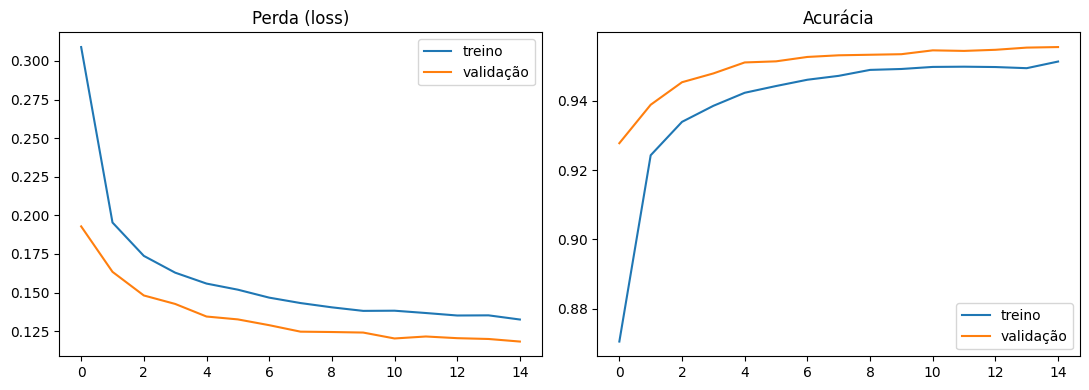

In [ ]:
# Curvas de treino
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(11, 4))
ax1.plot(historico.history["loss"], label="treino")
ax1.plot(historico.history["val_loss"], label="validação")
ax1.set_title("Perda (loss)")
ax1.legend()

ax2.plot(historico.history["accuracy"], label="treino")
ax2.plot(historico.history["val_accuracy"], label="validação")
ax2.set_title("Acurácia")
ax2.legend()
plt.tight_layout()
plt.show()


**Observação sobre as curvas de treino:** a perda de validação caiu de 0,19 (época 1) para 0,12 (época 15) de forma suave, com oscilações mínimas, e atingiu o menor valor justamente na última época. Não há sinais de overfitting: as curvas de treino e de validação ficam próximas o tempo todo, com a de validação sempre um pouco melhor que a de treino, o que é esperado pelo *dropout*, usado só durante o treino.

A maior parte do ganho acontece nas 3 primeiras épocas, em que a acurácia de validação sobe de 92,8% para 94,5%. As 12 épocas seguintes acrescentam apenas cerca de 1 ponto percentual, chegando a 95,6%. Esse comportamento é típico de transferência de aprendizado: a rede já chega sabendo a maior parte do que precisa e só ajusta a última camada. Como a perda de validação ainda estava caindo lentamente na época 15, a parada antecipada não foi acionada e o treino usou as 15 épocas previstas.

### Gráfico complementar: tempo de treino por época

Além da curva de acurácia e perda, é útil ver quanto tempo cada época levou. A primeiraépoca é sempre mais lenta, porque o TensorFlow ainda está preparando a execução.

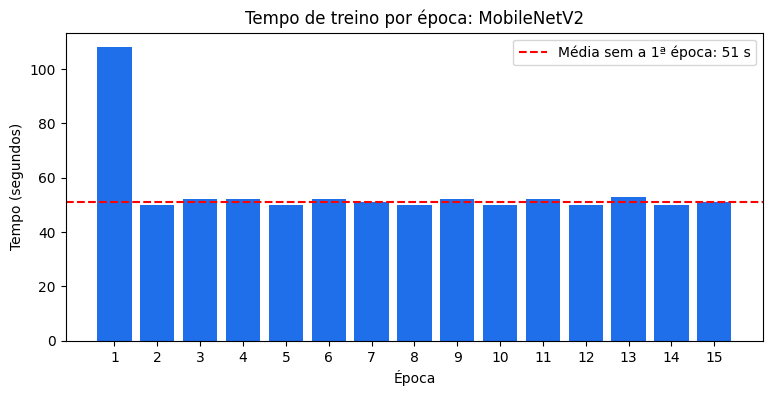

In [ ]:
# Tempos registrados nesta rodada (MobileNetV2, GPU T4), em segundos por época
tempos_epoca_mobilenet = [108, 50, 52, 52, 50, 52, 51, 50, 52, 50, 52, 50, 53, 50, 51]

media_sem_primeira = sum(tempos_epoca_mobilenet[1:]) / len(tempos_epoca_mobilenet[1:])

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(tempos_epoca_mobilenet) + 1), tempos_epoca_mobilenet, color="#1f6feb")
plt.axhline(media_sem_primeira, color="red", linestyle="--",
            label=f"Média sem a 1ª época: {media_sem_primeira:.0f} s")
plt.xticks(range(1, len(tempos_epoca_mobilenet) + 1))
plt.xlabel("Época")
plt.ylabel("Tempo (segundos)")
plt.title("Tempo de treino por época: MobileNetV2")
plt.legend()
plt.show()


**Observação sobre o tempo de treino:** a primeira época levou 108 segundos, cerca do dobro das demais, que ficaram estáveis entre 50 e 53 segundos, com média de 51 segundos. O treino completo das 15 épocas levou aproximadamente 14 minutos em GPU, um tempo viável para repetir o experimento sempre que a base de dados for atualizada.

## 7. Avaliação no conjunto de teste: acurácia, precisão, recall, F1 e matriz de confusão

O conjunto de **teste** não participa do treino nem da validação é usado apenas
aqui, uma vez, para medir o desempenho final de forma honesta.


Acurácia : 0.965
Precisão : 0.978
Recall   : 0.958
F1-score : 0.968


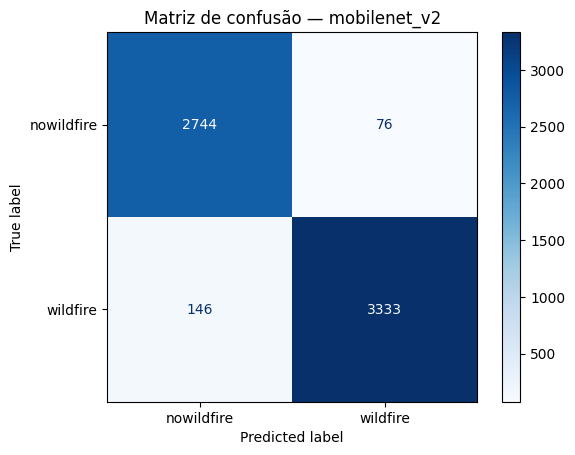

In [ ]:
import numpy as np
from sklearn.metrics import accuracy_score, precision_score, recall_score, f1_score, confusion_matrix, ConfusionMatrixDisplay

y_real, y_prob = [], []
for lote_x, lote_y in ds_teste:
    y_real.extend(lote_y.numpy().ravel().tolist())
    y_prob.extend(modelo.predict(lote_x, verbose=0).ravel().tolist())

y_real = np.array(y_real)
y_pred = (np.array(y_prob) >= 0.5).astype(int)

acuracia = accuracy_score(y_real, y_pred)
precisao = precision_score(y_real, y_pred)
recall = recall_score(y_real, y_pred)
f1 = f1_score(y_real, y_pred)

print(f"Acurácia : {acuracia:.3f}")
print(f"Precisão : {precisao:.3f}")
print(f"Recall   : {recall:.3f}")
print(f"F1-score : {f1:.3f}")

matriz = confusion_matrix(y_real, y_pred)
ConfusionMatrixDisplay(matriz, display_labels=NOMES_CLASSES).plot(cmap="Blues")
plt.title(f"Matriz de confusão: {MODELO}")
plt.show()


**Conclusão da matriz de confusão:** das 6.299 imagens de teste, o modelo acertou 6.077 (96,5%) e errou 222 (3,5%). A diagonal principal concentra quase todos os casos: 2.744 imagens sem incêndio e 3.333 imagens com incêndio foram classificadas corretamente, o que mostra que o modelo separa bem as duas classes, sem favorecer uma delas.

Os erros se dividem em dois tipos. Foram 76 falsos positivos (2,7% das 2.820 imagens sem incêndio), em que o modelo indicou incêndio onde não havia, e 146 falsos negativos (4,2% das 3.479 imagens com incêndio), em que o modelo deixou de indicar um incêndio real.

O ponto de atenção é que o modelo erra quase duas vezes mais para o lado dos falsos negativos do que para o lado dos falsos positivos. Para o Sentinela do Território, esse é justamente o erro mais grave, porque uma queimada real deixaria de ser confirmada. Por isso a precisão (97,8%) ficou acima do recall (95,8%): quando o modelo diz que há incêndio, ele quase sempre está certo, mas ainda deixa passar cerca de 4 em cada 100 incêndios reais. A seção 8 discute esses casos e a possibilidade de reduzir o limiar de decisão para diminuir os falsos negativos.

| Quadrante | Valor | Significado |
|---|---|---|
| Superior esquerdo | 2.744 | Sem incêndio, e o modelo acertou |
| Superior direito | 76 | Sem incêndio, mas o modelo indicou incêndio (falso positivo) |
| Inferior esquerdo | 146 | Com incêndio, mas o modelo não indicou (falso negativo) |
| Inferior direito | 3.333 | Com incêndio, e o modelo acertou |

### Gráficos complementares (curva ROC, precisão-recall e confiança do modelo)

Além da matriz de confusão, estes três gráficos ajudam a entender melhor o
comportamento do modelo e são bons para usar depois numa página/dashboard do
projeto, por serem mais visuais que uma tabela de números.


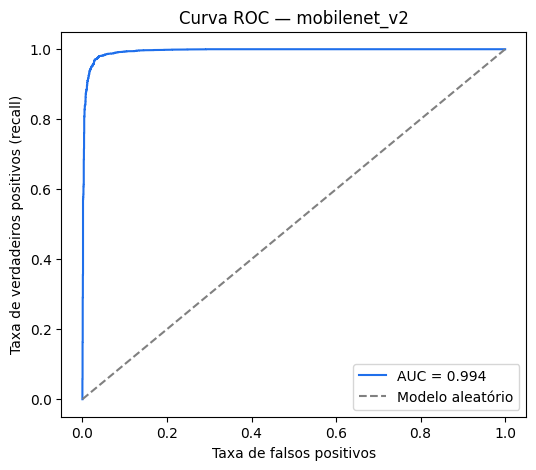

In [ ]:
from sklearn.metrics import roc_curve, roc_auc_score, precision_recall_curve

fpr, tpr, _ = roc_curve(y_real, y_prob)
auc = roc_auc_score(y_real, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(fpr, tpr, color="#1f6feb", label=f"AUC = {auc:.3f}")
plt.plot([0, 1], [0, 1], "--", color="gray", label="Modelo aleatório")
plt.xlabel("Taxa de falsos positivos")
plt.ylabel("Taxa de verdadeiros positivos (recall)")
plt.title(f"Curva ROC: {MODELO}")
plt.legend()
plt.show()


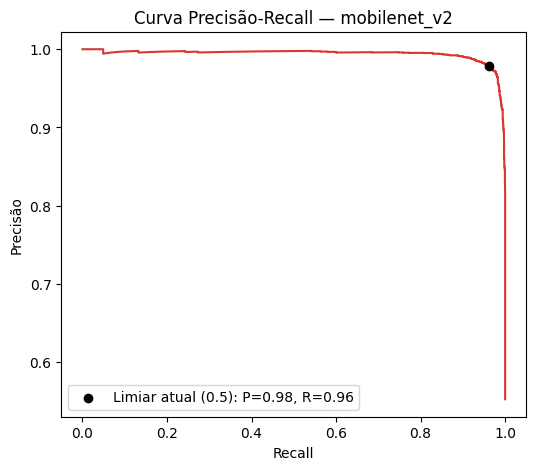

In [ ]:
precisoes, recalls, limiares = precision_recall_curve(y_real, y_prob)

plt.figure(figsize=(6, 5))
plt.plot(recalls, precisoes, color="#da3633")
plt.scatter([recall], [precisao], color="black", zorder=5, label=f"Limiar atual (0.5): P={precisao:.2f}, R={recall:.2f}")
plt.xlabel("Recall")
plt.ylabel("Precisão")
plt.title(f"Curva Precisão-Recall: {MODELO}")
plt.legend()
plt.show()


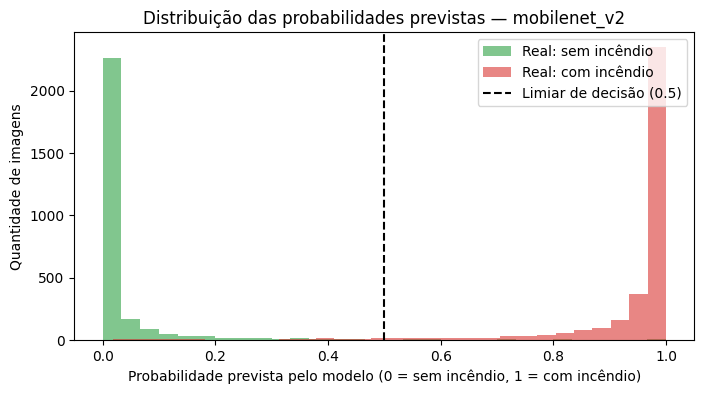

In [ ]:
plt.figure(figsize=(8, 4))
plt.hist(np.array(y_prob)[y_real == 0], bins=30, alpha=0.6, label="Real: sem incêndio", color="#2ea043")
plt.hist(np.array(y_prob)[y_real == 1], bins=30, alpha=0.6, label="Real: com incêndio", color="#da3633")
plt.axvline(0.5, color="black", linestyle="--", label="Limiar de decisão (0.5)")
plt.xlabel("Probabilidade prevista pelo modelo (0 = sem incêndio, 1 = com incêndio)")
plt.ylabel("Quantidade de imagens")
plt.title(f"Distribuição das probabilidades previstas: {MODELO}")
plt.legend()
plt.show()


**Como interpretar estes três gráficos (preencher depois de rodar):**

- **Curva ROC:** quanto mais a linha azul se aproxima do canto superior esquerdo (e quanto mais perto de 1 o AUC), melhor o modelo separa as duas classes em qualquer limiar de decisão, não só no 0.5 usado por padrão.

- **Curva Precisão-Recall:** mostra a troca entre falsos positivos e falsos negativos em diferentes limiares. O ponto preto marca onde o modelo está hoje (limiar 0.5) dá pra ver visualmente quanto de precisão se perderia ao mover o limiar para aumentar o recall (reduzir falsos negativos, como discutido na seção 8).

- **Histograma de confiança:** o ideal é ver os dois grupos de cor bem separados, um perto de 0 e outro perto de 1. Sobreposição no meio (perto do limiar 0.5) indica as imagens "difíceis" provavelmente as mesmas que viram falsos negativos/positivos.

**Resultado obtido nesta rodada:** o AUC foi de 0,994, muito próximo de 1, e a curva ROC fica praticamente colada no canto superior esquerdo. Isso indica que o modelo separa muito bem as duas classes em qualquer limiar de decisão, e não apenas no 0.5.

Na curva de precisão e recall, a precisão se mantém perto de 100% até o recall chegar a cerca de 95% e só cai de forma acentuada bem no final. O ponto preto (limiar 0.5, com precisão de 0,98 e recall de 0,96) está logo antes dessa queda, o que mostra que existe alguma margem para reduzir o limiar e ganhar recall, mas que ir longe demais custaria muita precisão.

No histograma, os dois grupos ficaram bem separados: a grande maioria das imagens sem incêndio recebeu probabilidade perto de 0 e a grande maioria das imagens com incêndio recebeu probabilidade perto de 1. A sobreposição perto do limiar 0.5 é pequena e corresponde às imagens difíceis, que são os 76 falsos positivos e os 146 falsos negativos da matriz de confusão.


### Tabela de resultados (rodada de 10/11, MobileNetV2)

| Métrica | Valor |
|---|---|
| Acurácia | 0.965 |
| Precisão | 0.978 |
| Recall | 0.958 |
| F1 score | 0.968 |
| Falsos negativos (nº de imagens) | 146 |
| Falsos positivos (nº de imagens) | 76 |

| | Previsto: sem incêndio | Previsto: com incêndio |
|---|---|---|
| **Real: sem incêndio** | 2.744 | 76 |
| **Real: com incêndio** | 146 | 3.333 |

## 8. Discussão dos falsos negativos

Neste problema, um **falso negativo** (o modelo diz "sem incêndio" quando na verdade **há** incêndio) é o erro mais grave: significa que uma queimada real não seria confirmada pela visão computacional, podendo retardar o acionamento de uma equipe. Um **falso positivo** (alarme indevido) é mais barato: no máximo gera uma verificação humana desnecessária.

Houve 146 falsos negativos (4,2% das 3.479 imagens com incêndio real). Ao observar 3 exemplos classificados incorretamente, nenhuma das imagens mostra sinais visíveis de fogo, fumaça ou área queimada. Elas aparecem como terreno exposto (possível pedreira), plantação costeira e um bairro residencial comum, todos com vegetação verde normal.
Isso sugere que o erro não está necessariamente na capacidade do modelo de reconhece fogo, mas no fato de que o rótulo "wildfire" do dataset provavelmente se refere à região ou ao risco da imagem, e não a uma evidência visual direta de incêndio na cena registrada. Trata-se de uma limitação do próprio dataset, não só do modelo.

Como o custo de um falso negativo é alto, uma melhoria possível é **baixar o limiar de decisão** (por exemplo, de 0.5 para 0.35), aceitando mais falsos positivos para reduzir falsos negativos. É uma troca explícita entre segurança e número de verificações humanas.

## 9. Salvar o modelo treinado

In [ ]:
PASTA_MODELOS = Path("/content/modelos")
PASTA_MODELOS.mkdir(exist_ok=True)

caminho_modelo = PASTA_MODELOS / f"queimada_{MODELO}.keras"
modelo.save(caminho_modelo)
print("Modelo salvo em:", caminho_modelo)

# Baixe este arquivo para o seu computador (ele é usado pelo módulo inferencia.py)
from google.colab import files  # type: ignore
files.download(str(caminho_modelo))


Modelo salvo em: /content/modelos/queimada_mobilenet_v2.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 10. Conclusão e aplicação real

O modelo treinado com MobileNetV2 atingiu 96,5% de acurácia no conjunto de teste, com precisão de 97,8% e recall de 95,8%. É um resultado consistente com o esperado para transferência de aprendizado em um problema de classificação binária com dados relativamente simples (satélite, duas classes bem definidas). Para este problema, consideramos o **recall** a métrica mais relevante, porque o custo de um falso negativo (não identificar uma queimada real) é maior do que o de um falso positivo (gerar uma verificação humana desnecessária). Dos 146 falsos negativos, a análise visual de exemplos mostrou que grande parte não tinha evidência visual clara de incêndio na própria imagem, o que aponta para uma limitação do dataset (rótulo por região ou risco, não necessariamente por fogo visível na cena) tanto quanto do modelo.

Com mais tempo, duas direções melhorariam o resultado: treinar por mais épocas com ajuste fino também das últimas camadas da rede usada como base (hoje totalmente congelada), e aumentar a base de dados com imagens de diferentes estações do ano e condições de iluminação, reduzindo a dependência de um único recorte visual por ocorrência. Para uso real, recomendamos manter a confirmação humana antes de qualquer acionamento de equipe. O modelo serve como uma segunda evidência de apoio à decisão, não como substituto do julgamento humano, especialmente dado o padrão de erro observado.

Este classificador é a peça de Visão Computacional do protótipo **Sentinela do
Território**: quando um cidadão relata uma queimada pelo assistente de voz (módulo de PLN), uma imagem de satélite da região pode ser passada por este modelo para dar uma segunda confirmação automática antes de a equipe de campo ser avisada, reduzindo acionamentos desnecessários sem depender só do relato humano.

---

# Extensão para a cidade: danos em estruturas

A disciplina também cita, no desafio geral do CitizenTech, o uso de Visão
Computacional para **cidades**. A proposta é reaproveitar exatamente o mesmo código acima, mudando apenas os dados, para detectar rachaduras e danos em fotos de construções enviadas pelo cidadão ou por um fiscal. A saída dessa classificação não aciona nada por conta própria: ela **abre e prioriza uma ordem de manutenção**, sempre com confirmação do gestor.

In [ ]:
# Extensão para a cidade: proposta de continuidade, não executada nesta entrega.
# Reaproveita exatamente as mesmas funções: carregar_conjunto() e montar_modelo()
MODELO_CIDADE = MODELO  # mesma arquitetura escolhida acima, por padrão

# Depois de baixar uma base de rachaduras e organizar em /content/rachaduras com a
# mesma estrutura train/valid/test usada acima, basta apontar CAMINHO_DADOS para ela
# e repetir os passos das seções 4 a 7:
#
#   CAMINHO_DADOS_CIDADE = Path("/content/rachaduras")
#   CAMINHO_DADOS = CAMINHO_DADOS_CIDADE
#   ds_treino = carregar_conjunto("train", embaralhar=True)
#   ds_val = carregar_conjunto("valid", embaralhar=False)
#   ds_teste = carregar_conjunto("test", embaralhar=False)
#   ... normalizar, montar_modelo(MODELO_CIDADE), treinar, avaliar (seções 4 a 7) ...
#
# Mantemos como comentário (em vez de duplicar todo o código) porque a estrutura de
# pastas das bases de rachaduras varia bastante. Adapte conforme o que for baixado.

### Tabela de resultados da extensão para a cidade

Esta extensão não foi executada nesta entrega. Ela está descrita como proposta de continuidade do projeto: para treinar o modelo, é preciso primeiro organizar uma base de imagens de rachaduras em concreto na mesma estrutura de pastas usada para as queimadas (train, valid e test, cada uma com uma subpasta por classe) e então repetir as seções 4 a 7. Por isso a tabela abaixo não tem valores.

| Métrica | Valor |
|---|---|
| Acurácia | Não executado |
| Precisão | Não executado |
| Recall | Não executado |
| F1 score | Não executado |


## 11. Tempo de inferência por imagem

O desafio geral cita desempenho em tempo real: uma foto enviada pelo cidadão precisa de uma resposta rápida. A célula abaixo mede o tempo médio de inferência por imagem (medido aqui em GPU, no Colab).


In [ ]:
import time

def medir_tempo_inferencia(modelo_treinado, dataset, n_lotes=5):
    tempos = []
    for i, (lote_x, _) in enumerate(dataset):
        if i >= n_lotes:
            break
        inicio = time.perf_counter()
        modelo_treinado.predict(lote_x, verbose=0)
        fim = time.perf_counter()
        tempos.append((fim - inicio) / lote_x.shape[0])
    media_ms = sum(tempos) / len(tempos) * 1000
    print(f"Tempo médio de inferência: {media_ms:.1f} ms por imagem")
    return media_ms

# Use o conjunto de teste já carregado (queimada ou cidade, o que estiver em ds_teste)
medir_tempo_inferencia(modelo, ds_teste)


Tempo médio de inferência: 5.8 ms por imagem


5.816866787500885

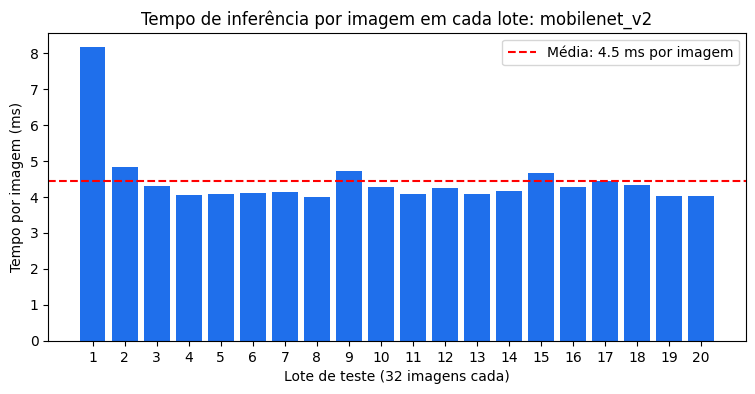

Mais rápido: 4.0 ms | Mais lento: 8.2 ms | Média: 4.5 ms


In [ ]:
# Gráfico: tempo de inferência por imagem em cada lote do conjunto de teste
N_LOTES = 20
tempos_ms = []
for i, (lote_x, _) in enumerate(ds_teste):
    if i >= N_LOTES:
        break
    inicio = time.perf_counter()
    modelo.predict(lote_x, verbose=0)
    fim = time.perf_counter()
    tempos_ms.append((fim - inicio) / lote_x.shape[0] * 1000)

media_ms = sum(tempos_ms) / len(tempos_ms)

plt.figure(figsize=(9, 4))
plt.bar(range(1, len(tempos_ms) + 1), tempos_ms, color="#1f6feb")
plt.axhline(media_ms, color="red", linestyle="--", label=f"Média: {media_ms:.1f} ms por imagem")
plt.xticks(range(1, len(tempos_ms) + 1))
plt.xlabel(f"Lote de teste ({TAMANHO_LOTE} imagens cada)")
plt.ylabel("Tempo por imagem (ms)")
plt.title(f"Tempo de inferência por imagem em cada lote: {MODELO}")
plt.legend()
plt.show()

print(f"Mais rápido: {min(tempos_ms):.1f} ms | Mais lento: {max(tempos_ms):.1f} ms | Média: {media_ms:.1f} ms")

**Observação:** o tempo médio de inferência do MobileNetV2 em GPU foi de 5,8 ms por imagem na medição com 5 lotes e de 4,5 ms na medição com 20 lotes, mostrada no gráfico. A diferença se explica pelo primeiro lote, que levou cerca de 8 ms por imagem porque o TensorFlow ainda está preparando a execução. A partir do segundo lote o tempo fica estável, entre 4 e 5 ms por imagem, o que equivale a mais de 200 imagens por segundo.

Esse tempo foi medido apenas para o MobileNetV2. A seção 14 compara as métricas de acerto dos três modelos, mas não mede o tempo de inferência do EfficientNetB0 e do ResNet50. Em CPU o tempo seria maior do que o medido aqui, mas um modelo deste tamanho (2,26 milhões de parâmetros, dos quais só 1.281 treináveis) tende a responder em bem menos de 1 segundo por imagem, o que é compatível com o cenário de uma foto enviada pelo cidadão com resposta em poucos segundos.

## 12. Justificativa da arquitetura

Com cerca de 5 ms por imagem em GPU, o MobileNetV2 responde com folga dentro do que se espera de tempo real para este caso de uso, já que uma foto enviada pelo cidadão não precisa de resposta instantânea e alguns segundos já atendem. O MobileNetV2 foi desenhado especificamente para ser leve (2,26 milhões de parâmetros no total, quase todos congelados), o que também permitiria rodar em CPU comum, sem GPU dedicada, com tempo ainda aceitável. Um modelo como o ResNet50 é bem maior (cerca de 25 milhões de parâmetros) e por isso tende a ser mais lento para treinar e para responder. A comparação de acerto entre os três modelos está na seção 14. O tempo de inferência dos outros dois modelos não foi medido neste notebook.

## 13. Próximos passos: integração com a interface

O módulo `inferencia.py` (entregue junto com este notebook, fora do Colab) carrega o arquivo `.keras` salvo na seção 9 e expõe uma função `classificar_imagem()` pronta para ser chamada por uma interface. Um exemplo seria uma nova aba do aplicativo do assistente de voz (PLN), onde o cidadão ou o fiscal envia uma foto pelo celular e recebe:

1. A classificação do modelo (por exemplo: "possível incêndio, confiança de 82%").
2. Um aviso claro de que a decisão final é de um gestor humano, nunca automática.

Essa integração é **opcional** e depende do tempo disponível do grupo (ver quadro de integração do relatório de Governança), mas o código já está pronto para ser plugado.


## 13.1 Diferenças entre MobileNetV2, EfficientNetB0 e ResNet50

Antes de rodar a comparação, vale entender por que essas três arquiteturas foram
escolhidas (características gerais, conhecidas da literatura a comparação real,
com os números deste dataset, vem na seção 14 depois de rodar):

| | MobileNetV2 | EfficientNetB0 | ResNet50 |
|---|---|---|---|
| Parâmetros totais (aprox.) | 3,5 milhões | 5,3 milhões | 25,6 milhões |
| Ideia central | Convoluções "depthwise separable" muito mais baratas computacionalmente que convoluções normais | Escala profundidade, largura e resolução da imagem juntas, de forma balanceada | Conexões residuais ("atalhos") que permitem treinar redes bem mais profundas sem perder desempenho |
| Pensada para | Rodar em celular/dispositivos com pouco poder de processamento | Bom equilíbrio entre precisão e custo computacional | Alta precisão, sem muita preocupação original com tamanho/velocidade |
| Expectativa de velocidade | Mais rápida das três | Intermediária | Mais lenta das três |
| Expectativa de precisão | Boa, mas geralmente a menor das três | Geralmente a melhor relação precisão/custo | Pode ter a maior precisão bruta, à custa de mais tempo |

Por isso elas foram escolhidas juntas: dá para comparar, com o mesmo dataset e o
mesmo código, se a teoria ("mais parâmetros tende a precisão maior e velocidade
menor") se confirma na prática e qual modelo faz mais sentido para o caso de uso do projeto (resposta rápida a uma foto de cidadão, possivelmente sem GPU disponível em produção).


---

# 14. Comparação dos três modelos (MobileNetV2, EfficientNetB0, ResNet50)

Esta seção treina e avalia os três modelos em sequência, no mesmo notebook, e
monta os gráficos comparativos para o relatório de Governança. Reaproveita
`montar_modelo()`, `ds_treino`, `ds_val` e `ds_teste` já criados nas seções
anteriores não precisa rodar nada de novo antes desta seção, só rodar as
células abaixo em ordem.

Como treina três modelos, um atrás do outro, essa seção demora bem mais que
rodar um só espere de 30 a 60 minutos no total, dependendo da GPU.


In [ ]:
def treinar_e_avaliar(nome_modelo: str, epocas: int = 15) -> dict:
    """Monta, treina e avalia um modelo, devolvendo tudo que os gráficos precisam."""
    print(f"\n=== Treinando {nome_modelo} ===")
    modelo_atual = montar_modelo(nome_modelo)

    parada_antecipada = tf.keras.callbacks.EarlyStopping(
        monitor="val_loss", patience=3, restore_best_weights=True
    )
    historico = modelo_atual.fit(
        ds_treino, validation_data=ds_val, epochs=epocas, callbacks=[parada_antecipada]
    )

    y_real, y_prob = [], []
    for lote_x, lote_y in ds_teste:
        y_real.extend(lote_y.numpy().ravel().tolist())
        y_prob.extend(modelo_atual.predict(lote_x, verbose=0).ravel().tolist())
    y_real = np.array(y_real)
    y_pred = (np.array(y_prob) >= 0.5).astype(int)

    metricas = {
        "acuracia": accuracy_score(y_real, y_pred),
        "precisao": precision_score(y_real, y_pred),
        "recall": recall_score(y_real, y_pred),
        "f1": f1_score(y_real, y_pred),
    }
    matriz = confusion_matrix(y_real, y_pred)
    return {
        "modelo": modelo_atual,
        "historico": historico.history,
        "metricas": metricas,
        "matriz": matriz,
    }


NOMES_MODELOS = ["mobilenet_v2", "efficientnet_b0", "resnet50"]
resultados = {}
for nome in NOMES_MODELOS:
    resultados[nome] = treinar_e_avaliar(nome)

print("\nTreino dos três modelos concluído.")



=== Treinando mobilenet_v2 ===


/tmp/ipykernel_2114/1919805657.py:7: UserWarning: `input_shape` is undefined or non-square, or `rows` is not in [96, 128, 160, 192, 224]. Weights for input shape (224, 224) will be loaded as the default.
  base = tf.keras.applications.MobileNetV2(include_top=False, weights="imagenet", input_tensor=entrada)


Epoch 1/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 76s 66ms/step - accuracy: 0.8509 - loss: 0.3368 - val_accuracy: 0.9229 - val_loss: 0.2048
Epoch 2/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 66s 54ms/step - accuracy: 0.9224 - loss: 0.2000 - val_accuracy: 0.9392 - val_loss: 0.1688
Epoch 3/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 51s 54ms/step - accuracy: 0.9328 - loss: 0.1770 - val_accuracy: 0.9448 - val_loss: 0.1510
Epoch 4/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 51s 54ms/step - accuracy: 0.9388 - loss: 0.1638 - val_accuracy: 0.9478 - val_loss: 0.1408
Epoch 5/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 51s 54ms/step - accuracy: 0.9413 - loss: 0.1588 - val_accuracy: 0.9511 - val_loss: 0.1366
Epoch 6/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 82s 54ms/step - accuracy: 0.9449 - loss: 0.1501 - val_accuracy: 0.9519 - val_loss: 0.1314
Epoch 7/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 83s 55ms/step - accuracy: 0.9444 - loss: 0.1486 - val_accuracy: 0.9532 - val_loss: 0.1288
Epoch 8/15
946/946 ━━━━━━━━━━━━━━━━━━━━ 81s 54ms/step - accuracy: 0.9468 - loss: 0.1449 - 

## 14.1 Tabela comparativa de métricas

---



In [ ]:
import pandas as pd

tabela_comparativa = pd.DataFrame(
    {nome: resultados[nome]["metricas"] for nome in NOMES_MODELOS}
).T
tabela_comparativa.columns = ["Acurácia", "Precisão", "Recall", "F1-score"]
tabela_comparativa.index.name = "Modelo"
display(tabela_comparativa.style.format("{:.3f}"))


,Acurácia,Precisão,Recall,F1-score
Modelo,,,,
mobilenet_v2,0.966,0.978,0.961,0.969
efficientnet_b0,0.597,0.578,0.997,0.732
resnet50,0.879,0.870,0.918,0.893


**Conclusão da tabela comparativa:** o MobileNetV2 teve o melhor resultado geral, com 96,6% de acurácia, 97,8% de precisão, 96,1% de recall e F1 de 0,969. É o único dos três com todas as métricas acima de 96%, ou seja, acerta bem tanto as imagens com incêndio quanto as imagens sem incêndio.

O EfficientNetB0 tem o maior recall da tabela (99,7%), mas esse número isolado engana. A precisão dele é de apenas 57,8% e a acurácia de 59,7%, valores muito próximos dos 55% que seriam obtidos por um modelo que respondesse "com incêndio" para todas as imagens do teste. Isso indica que ele quase não distingue as duas classes: encontra praticamente todos os incêndios porque classifica quase tudo como incêndio, o que geraria um alarme falso para a maior parte das imagens sem fogo.

O ResNet50 fica em posição intermediária, com 87,9% de acurácia e 91,8% de recall, abaixo do MobileNetV2 em todas as métricas.

Como o recall é a métrica mais importante para este problema, a tabela mostra por que ele não pode ser analisado sozinho: um recall alto só tem valor quando vem acompanhado de boa precisão. Considerando o conjunto das métricas, o MobileNetV2 é o modelo mais indicado para o Sentinela do Território.

**Ressalva:** o resultado contraria a expectativa da seção 13.1, de que os modelos maiores acertariam mais. A causa provável é a preparação das imagens, e não as arquiteturas: a divisão dos pixels por 255 feita na seção 4 é adequada para o MobileNetV2, mas o EfficientNetB0 e o ResNet50 do Keras esperam as imagens em outra escala. Essa hipótese não foi testada neste notebook, e uma comparação justa exigiria repetir o treino aplicando a cada modelo a preparação que ele espera.

## 14.2 Gráfico de barras comparando as métricas

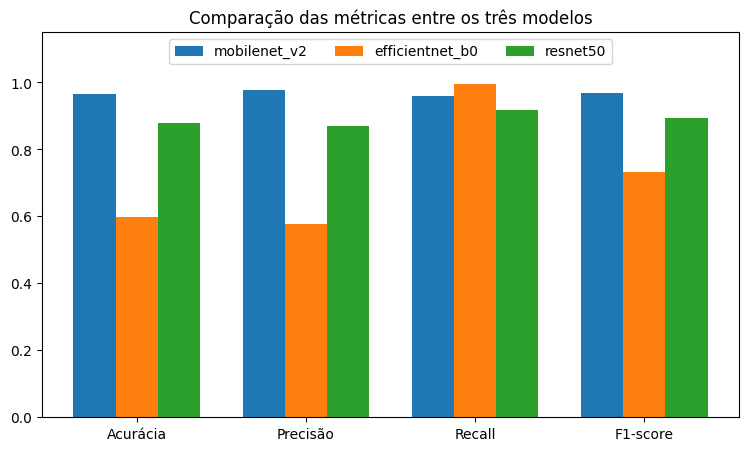

In [ ]:
nomes_metricas = ["acuracia", "precisao", "recall", "f1"]
rotulos_metricas = ["Acurácia", "Precisão", "Recall", "F1-score"]

x = np.arange(len(nomes_metricas))
largura = 0.25

fig, ax = plt.subplots(figsize=(9, 5))
for i, nome in enumerate(NOMES_MODELOS):
    valores = [resultados[nome]["metricas"][m] for m in nomes_metricas]
    ax.bar(x + i * largura, valores, largura, label=nome)

ax.set_xticks(x + largura)
ax.set_xticklabels(rotulos_metricas)
ax.set_ylim(0, 1.15)
ax.set_yticks(np.arange(0, 1.01, 0.2))
ax.set_title("Comparação das métricas entre os três modelos")
ax.legend(loc="upper center", ncol=3)
plt.show()


**Conclusão do gráfico de barras:** o gráfico deixa visível o que a tabela mostra em números. As barras azuis do MobileNetV2 são altas e quase do mesmo tamanho nas quatro métricas, todas acima de 0,96, o que indica um modelo equilibrado, que não ganha em uma métrica à custa de outra.

As barras laranja do EfficientNetB0 têm o comportamento oposto. A do recall é a mais alta de todo o gráfico (0,997), mas as de acurácia (0,597) e precisão (0,578) são as mais baixas, com uma diferença de cerca de 40 pontos percentuais entre elas. Esse desequilíbrio é o sinal visual de um modelo que classifica quase tudo como incêndio: ele encontra praticamente todos os incêndios reais, mas erra a maior parte das imagens sem fogo.

As barras verdes do ResNet50 ficam em um nível intermediário e também são
equilibradas, entre 0,87 e 0,92, mas sempre abaixo das do MobileNetV2.

O gráfico reforça que o melhor modelo não é o que tem a barra mais alta em uma única métrica, e sim o que mantém todas as barras altas ao mesmo tempo. Por esse critério, o MobileNetV2 é o mais indicado.

## 14.3 Curvas de treino sobrepostas (as três juntas)

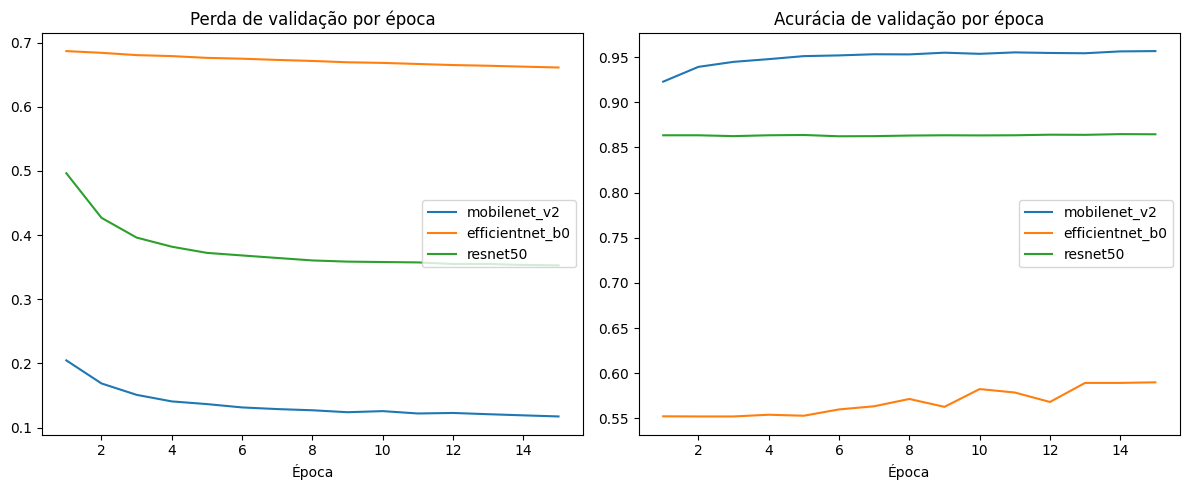

In [ ]:
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 5))
for nome in NOMES_MODELOS:
    h = resultados[nome]["historico"]
    epocas = range(1, len(h["val_loss"]) + 1)
    ax1.plot(epocas, h["val_loss"], label=nome)
    ax2.plot(epocas, h["val_accuracy"], label=nome)

ax1.set_title("Perda de validação por época")
ax1.set_xlabel("Época")
ax1.legend(loc="center right")

ax2.set_title("Acurácia de validação por época")
ax2.set_xlabel("Época")
ax2.legend(loc="center right")
plt.tight_layout()
plt.show()

**Conclusão das curvas de treino:** as curvas mostram que os três modelos aprenderam de formas muito diferentes ao longo das 15 épocas.

O MobileNetV2 (azul) tem o comportamento esperado de um treino saudável: a perda de validação cai de cerca de 0,21 para 0,12 e a acurácia sobe de cerca de 92% para perto de 96%, com a maior parte do ganho nas primeiras épocas e estabilização em seguida.

O ResNet50 (verde) reduz a perda de cerca de 0,50 para 0,35, mas a acurácia de
validação fica praticamente parada em torno de 86% do início ao fim. O modelo fica mais confiante nas respostas que já dava, mas não passa a acertar mais imagens.

O EfficientNetB0 (laranja) quase não aprende. A perda sai de cerca de 0,69 e termina em 0,66, muito perto do valor de 0,69 que corresponde a um modelo que responde ao acaso em um problema de duas classes. A acurácia começa em 55%, exatamente a proporção de imagens com incêndio na validação, o que indica um modelo que classifica tudo como incêndio, e chega a apenas 59% na última época.

As curvas mostram que o resultado ruim do EfficientNetB0 não se deve à falta de
épocas: a linha quase reta desde o início indica que as características que chegam à camada final carregam pouca informação útil, o que é compatível com a hipótese de que as imagens foram entregues ao modelo em uma escala diferente da que ele espera. Entre os três, apenas o MobileNetV2 apresenta uma curva de aprendizado adequada.

## 14.4 Matrizes de confusão lado a lado

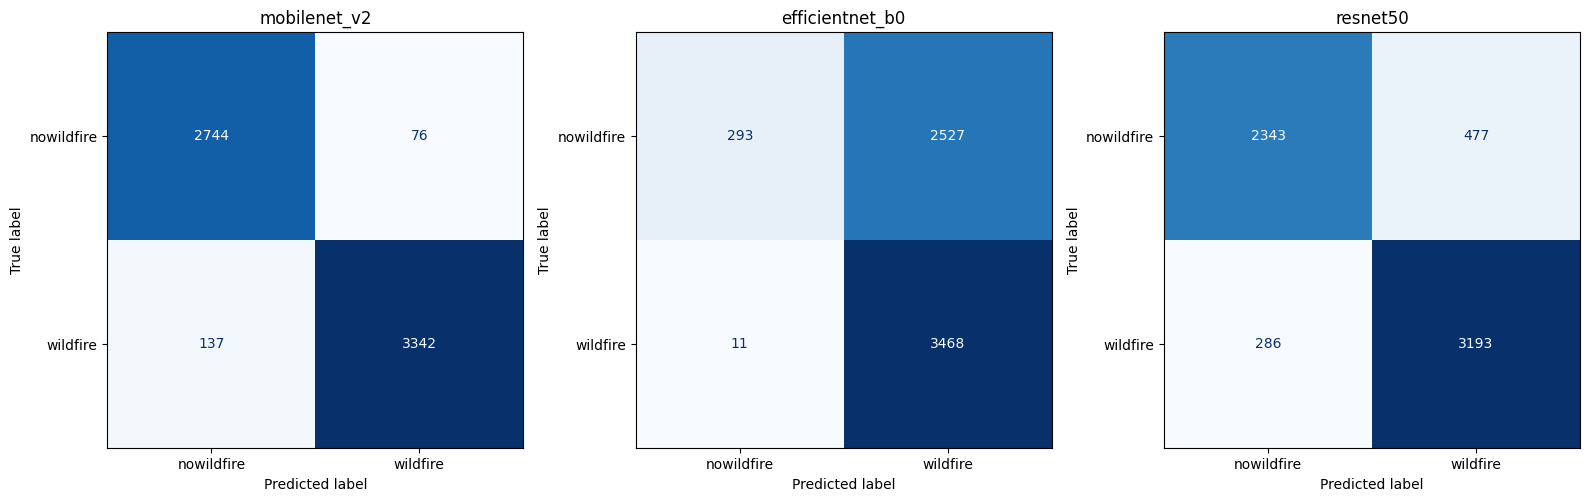

In [ ]:
fig, eixos = plt.subplots(1, 3, figsize=(16, 5))
for eixo, nome in zip(eixos, NOMES_MODELOS):
    ConfusionMatrixDisplay(resultados[nome]["matriz"], display_labels=NOMES_CLASSES).plot(
        ax=eixo, cmap="Blues", colorbar=False
    )
    eixo.set_title(nome)
plt.tight_layout()
plt.show()


**Conclusão das matrizes de confusão:** as três matrizes usam as mesmas 6.299 imagens de teste (2.820 sem incêndio e 3.479 com incêndio), então os números podem ser comparados diretamente.

| Modelo | Acertos sem incêndio | Falsos positivos | Falsos negativos | Acertos com incêndio |
|---|---|---|---|---|
| MobileNetV2 | 2.744 | 76 (2,7%) | 137 (3,9%) | 3.342 |
| EfficientNetB0 | 293 | 2.527 (89,6%) | 11 (0,3%) | 3.468 |
| ResNet50 | 2.343 | 477 (16,9%) | 286 (8,2%) | 3.193 |

Os percentuais são calculados sobre o total real de cada classe: falsos positivos sobre 2.820 e falsos negativos sobre 3.479.

O MobileNetV2 é o único com a diagonal principal forte nos dois quadrantes. Ele erra pouco para os dois lados, com 213 erros no total, o que corresponde a 3,4% do teste.

O EfficientNetB0 tem o menor número de falsos negativos (11), mas a matriz mostra o motivo: ele respondeu "com incêndio" para 5.995 das 6.299 imagens (95%) e acertou apenas 293 das 2.820 imagens sem incêndio. O modelo não separa as classes, apenas classifica quase tudo como incêndio. Na prática, geraria um alarme falso para cerca de 9 em cada 10 imagens sem fogo.

O ResNet50 fica no meio, mas perde para o MobileNetV2 nos dois tipos de erro: tem cerca do dobro de falsos negativos (286 contra 137) e mais de seis vezes os falsos positivos (477 contra 76).

Como o falso negativo é o erro mais grave para o Sentinela do Território, seria
tentador escolher o modelo com menos falsos negativos. As matrizes mostram que essa leitura isolada está errada: um modelo que quase nunca deixa passar um incêndio, mas acusa incêndio em quase tudo, não serve como segunda evidência para confirmar um relato. Considerando os dois tipos de erro, o MobileNetV2 é o modelo mais confiável desta rodada.

## 14.5 Salvar e baixar os três modelos treinados

Cada arquivo baixa separadamente (o navegador pode perguntar se você permite
vários downloads de uma vez permita).


In [ ]:
for nome in NOMES_MODELOS:
    caminho = PASTA_MODELOS / f"queimada_{nome}.keras"
    resultados[nome]["modelo"].save(caminho)
    print("Salvo:", caminho)
    files.download(str(caminho))


Salvo: /content/modelos/queimada_mobilenet_v2.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: /content/modelos/queimada_efficientnet_b0.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

Salvo: /content/modelos/queimada_resnet50.keras


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

## 14.6 Conclusão comparativa

Os três modelos foram treinados com o mesmo código, os mesmos dados e as mesmas 15 épocas, e avaliados nas mesmas 6.299 imagens de teste.

| Modelo | Recall | Falsos negativos | Falsos positivos | Observação |
|---|---|---|---|---|
| MobileNetV2 | 96,1% | 137 | 76 | Melhor resultado geral. Único com todas as métricas acima de 96% e com poucos erros dos dois tipos. |
| EfficientNetB0 | 99,7% | 11 | 2.527 | Maior recall, mas sem valor prático: classifica quase tudo como incêndio e erra cerca de 9 em cada 10 imagens sem fogo. |
| ResNet50 | 91,8% | 286 | 477 | Resultado intermediário. Fica abaixo do MobileNetV2 em todas as métricas e nos dois tipos de erro. |

**Modelo recomendado:** o MobileNetV2. O recall é a métrica mais importante para este problema, mas só tem valor quando o modelo também acerta as imagens sem incêndio. Por esse critério, o MobileNetV2 é o que deixa passar menos incêndios reais entre os modelos que de fato distinguem as duas classes. Ele também é o mais leve dos três (2,26 milhões de parâmetros) e respondeu em cerca de 5 ms por imagem em GPU (seção 11), o que atende ao cenário de resposta rápida a uma foto enviada pelo cidadão.

**Limitações desta comparação:**

1. O resultado contraria a expectativa da seção 13.1, de que os modelos maiores
   acertariam mais. A causa provável é a preparação das imagens: a divisão dos pixels por 255, feita na seção 4, é adequada para o MobileNetV2, mas o EfficientNetB0 e o ResNet50 do Keras esperam as imagens em outra escala. Essa hipótese não foi testada neste notebook.
2. O tempo de inferência foi medido apenas para o MobileNetV2, então a comparação de velocidade entre os três modelos se apoia nas características gerais descritas na seção 13.1, e não em medições próprias.

**Próximo passo:** repetir a seção 14 aplicando a cada modelo a preparação de imagens que ele espera e medindo o tempo de inferência dos três. Só então será possível afirmar qual arquitetura é de fato a melhor para este dataset. Com os resultados obtidos até aqui, o MobileNetV2 é a escolha do projeto.